# 02 - Genome composition: the basic measurements

**The four features we measure**, all from the paper:

| Feature | What it counts |
|---|---|
| **GC content** | fraction of all letters that are G or C |
| **CpG** | a C immediately followed by a G |
| **GpC** | a G followed by a C |
| **GpG** | a G followed by a G |
| **CpC** | a C followed by a C |

For each dinucleotide we also compute the **O/E ratio** (observed / expected):

> O/E = frequency(XY) / (frequency(X) x frequency(Y))

O/E near **1.0** means the pair occurs about as often as chance predicts. Below **1.0** means
the virus has fewer of them than expected - the pair is *suppressed*. This matters because the
human antiviral protein ZAP recognises viral RNA at CpG sites, so viruses that circulate in
humans long-term tend to carry fewer CpGs than chance would give them.


In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; R scripts expect to run from here
pd.set_option("display.width", 120)

def run_r(script):
    """Run one of the R figure scripts from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))


In [2]:
d = pd.read_csv("../data/processed/rsv_features.tsv", sep="\t")
FEATS = ["gc_content", "oe_CG", "oe_GC", "oe_GG", "oe_CC"]
d.groupby("Subtype")[FEATS].mean().round(4)

,gc_content,oe_CG,oe_GC,oe_GG,oe_CC
Subtype,,,,,
A,0.3344,0.2361,0.9956,1.1303,1.0635
B,0.3364,0.2408,1.0864,1.0535,1.0083


### Reading that table

**CpG O/E is about 0.24 in both subtypes.** That is strong suppression: RSV carries only
a quarter of the CpG dinucleotides that its own base composition would predict. The other
three dinucleotides sit near or above 1.0, so this is specific to CpG rather than a
general property of the genome.

RSV-A and RSV-B differ, but the differences in GC content are small (0.3344 vs 0.3364).
The dinucleotide ratios separate them more clearly.

## Figures

These are produced by `R/figures.R`, which reads the same feature table. Running it here
keeps the notebook and the files in `results/figures/` in step.

In [3]:
run_r("R/figures.R")

Figures written to results/figures/


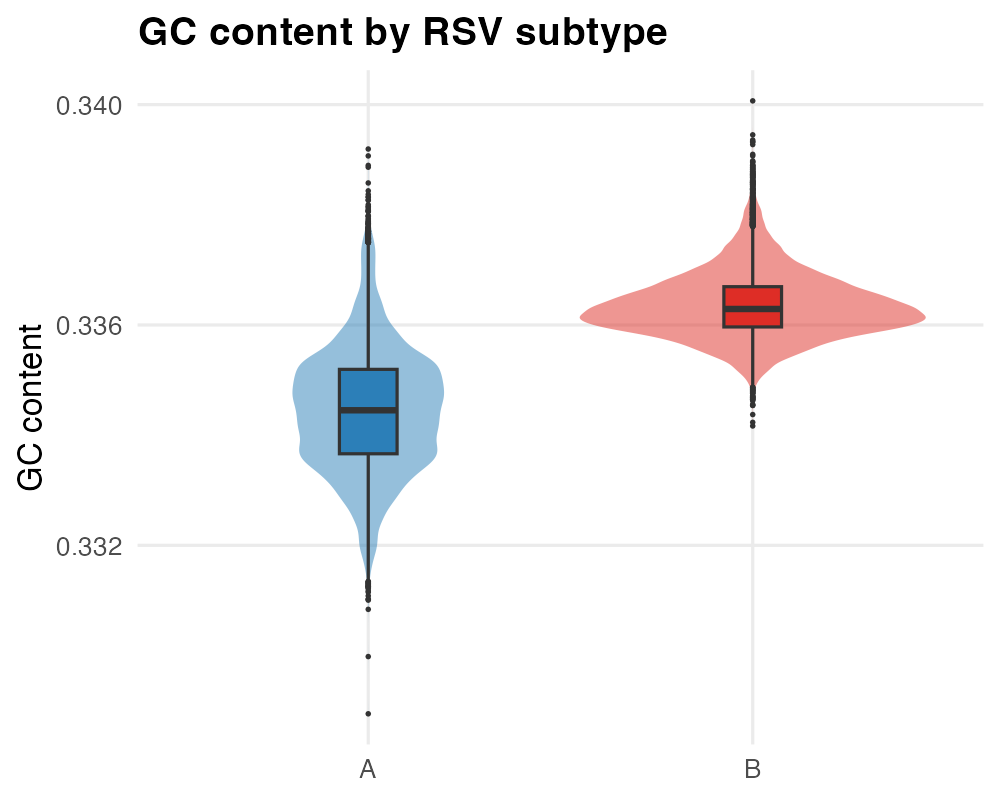

In [4]:
show("fig1_gc_by_subtype.png")

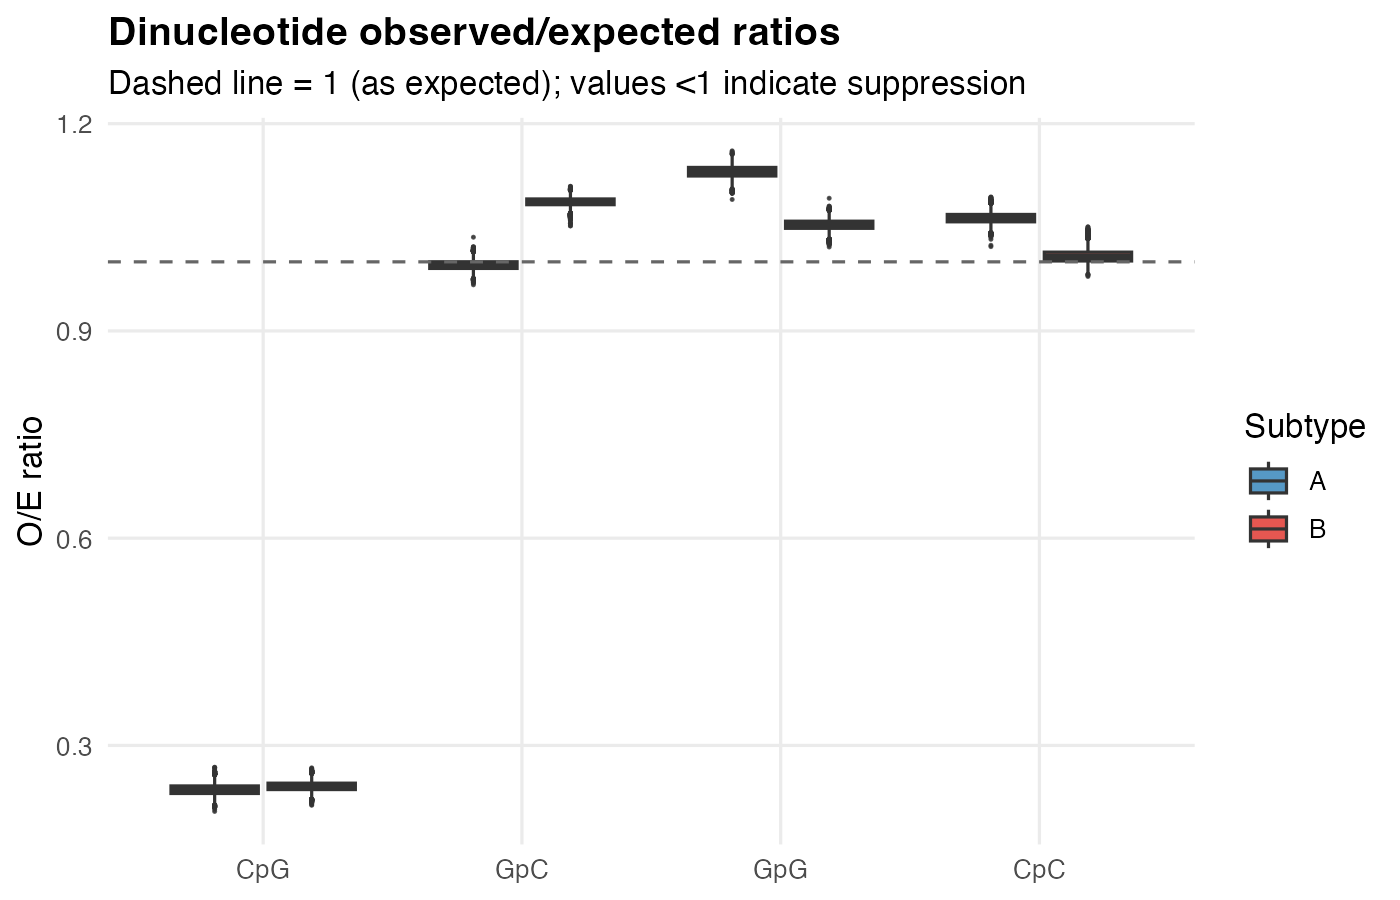

In [5]:
show("fig2_oe_dinuc_by_subtype.png")

The dashed line in the second figure marks O/E = 1. Only CpG sits far below it. GpC, GpG
and CpC hover around or above 1, so whatever is removing CpG is not simply removing G and
C letters in general.

## Does composition change over the years?

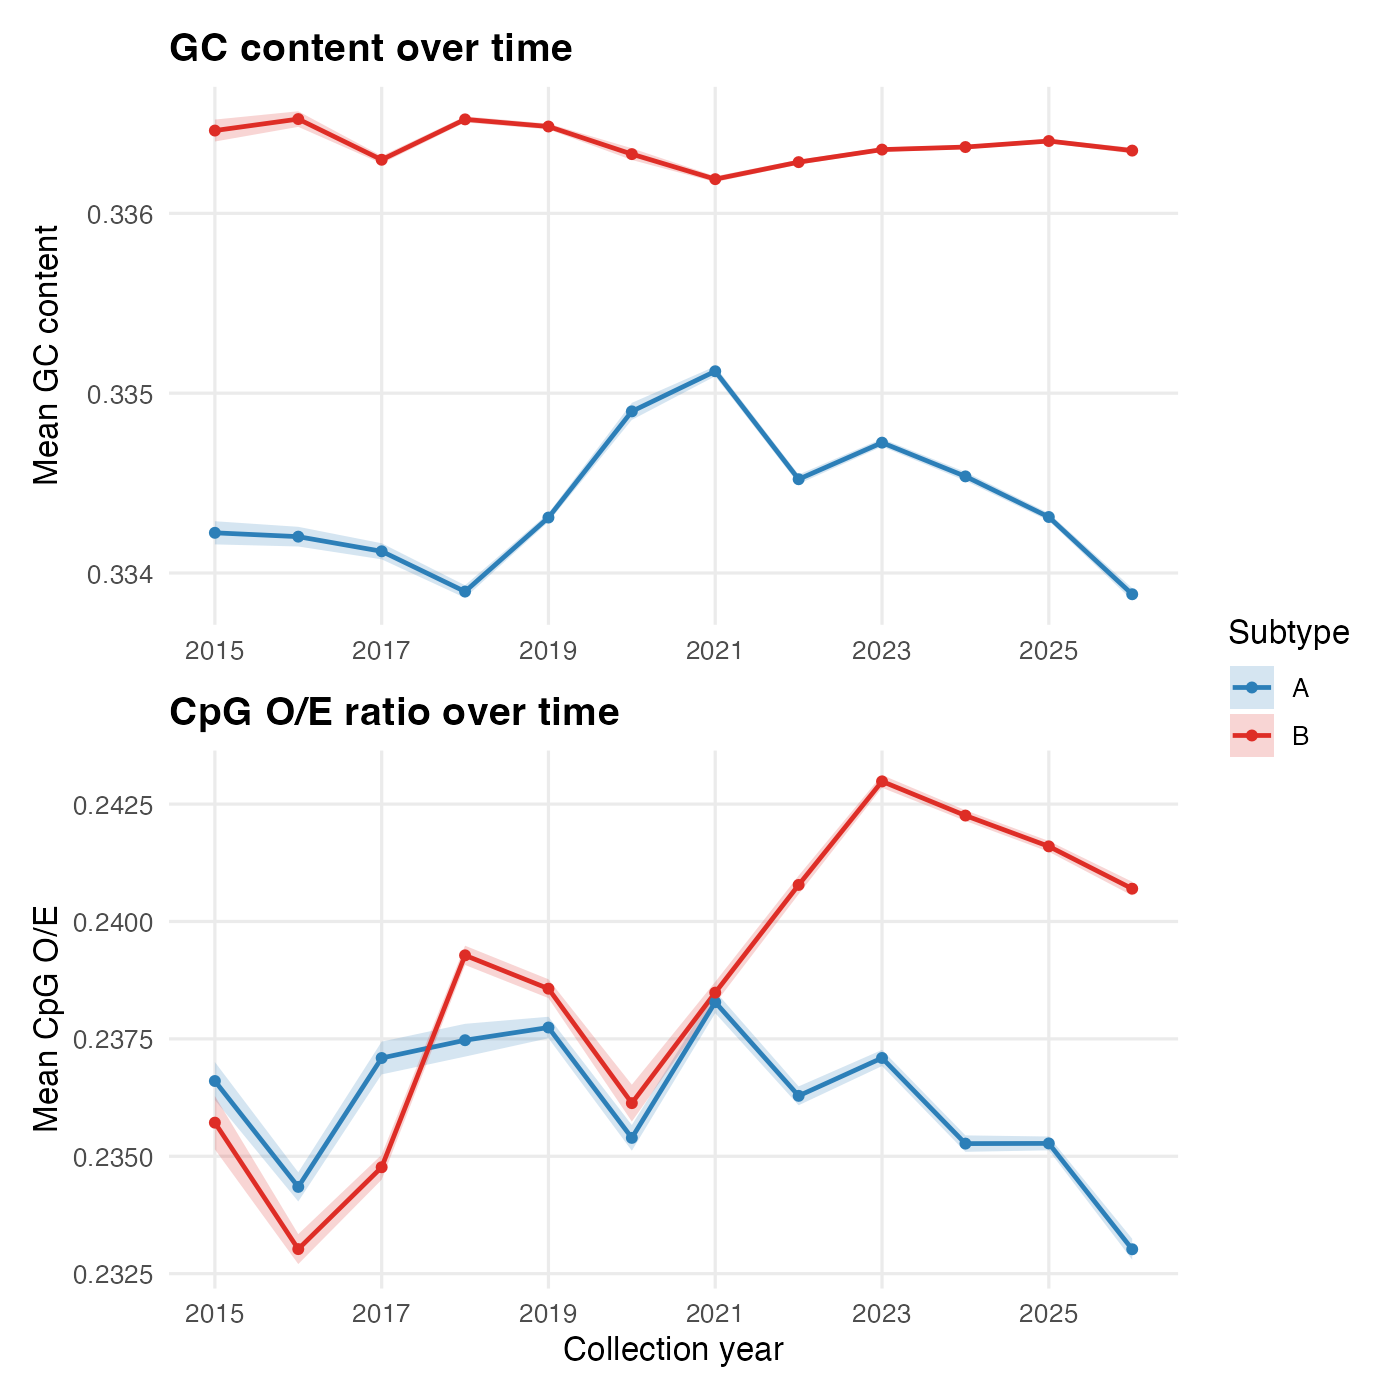

In [6]:
show("fig3_yearly_trends.png")

There is movement, and RSV-A and RSV-B seem to go in different directions after 2021.
**Be careful with this plot.** Notebook 04 shows that most of this apparent trend is not
the virus changing - it is one lineage replacing another. We come back to it there.